# IEEE-CIS E-Commerce Fraud Detection & Risk Scoring

## Notebook 03 — Calibration, Operating Decisions and Explainability

### Objective

Notebook 02 selected an unweighted 63-leaf LightGBM model using chronological
development data.

This notebook converts that ranking model into a complete fraud-screening
workflow.

The main steps are:

- refit the selected model on the full development period;
- assess and calibrate predicted fraud probabilities;
- select an operating policy using later transactions;
- quantify review workload, precision, recall, and fraud capture;
- evaluate the locked system on the reserved final holdout;
- explain model behavior and analyze important error patterns.

Model selection, probability calibration, and operating-threshold selection are
completed before final-holdout performance is evaluated.

Throughout this notebook, `pr_auc` refers to average precision calculated with
`average_precision_score`.

## Evaluation Protocol

The selected model specification is refitted using all transactions from
relative days **1–127**.

The reserved post-development period is then divided chronologically:

- **days 128–141:** fit probability calibration;
- **days 142–154:** compare calibration methods and select the operating policy;
- **days 155–182:** final holdout evaluation.

The decision-selection period is a tuning period rather than an unbiased final
test set. Final performance is reported only on the later holdout.

## Environment and Data Reconstruction

This notebook uses the same deterministic ingestion and preprocessing workflow
established in the previous notebooks.

The raw IEEE-CIS training tables are retrieved from Kaggle, numeric storage is
downcast for memory efficiency, transaction and identity records are merged,
and the previously selected row-level missingness features are reconstructed.

No exploratory or model-selection decisions are repeated in this notebook.

In [1]:
!pip -q install -U kaggle lightgbm

In [2]:
from pathlib import Path
import gc
import os
import subprocess

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import userdata

import lightgbm as lgb

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss
)

from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression

from scipy.special import logit

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

In [3]:
# Kaggle authentication

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

In [4]:
# Downloads the two source tables

REPO_ROOT = Path(
    "/content/ecommerce-fraud-risk-ieee-cis"
)

FIGURES_DIR = (
    REPO_ROOT
    / "reports"
    / "figures"
)

TABLES_DIR = (
    REPO_ROOT
    / "reports"
    / "tables"
)

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

TABLES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

DATA_DIR = Path("/content/data/raw")
DATA_DIR.mkdir(
    parents=True,
    exist_ok=True
)

COMPETITION = "ieee-fraud-detection"

files_to_download = [
    "train_transaction.csv",
    "train_identity.csv"
]

for filename in files_to_download:
    subprocess.run(
        [
            "kaggle",
            "competitions",
            "download",
            COMPETITION,
            "-f",
            filename,
            "-p",
            str(DATA_DIR)
        ],
        check=True
    )

In [5]:
# Loads the two source tables

TRANSACTION_PATH = DATA_DIR / "train_transaction.csv.zip"
IDENTITY_PATH = DATA_DIR / "train_identity.csv.zip"

transactions = pd.read_csv(
    TRANSACTION_PATH,
    compression="zip"
)

identity = pd.read_csv(
    IDENTITY_PATH,
    compression="zip"
)

print("Transactions:", transactions.shape)
print("Identity:", identity.shape)

Transactions: (590540, 394)
Identity: (144233, 41)


### Numeric Memory Optimization

In [6]:
def reduce_numeric_memory(df):
    int_cols = df.select_dtypes(include=["int64"]).columns
    float_cols = df.select_dtypes(include=["float64"]).columns

    for col in int_cols:
        df[col] = pd.to_numeric(
            df[col],
            downcast="integer"
        )

    for col in float_cols:
        df[col] = pd.to_numeric(
            df[col],
            downcast="float"
        )

    return df

In [7]:
transactions = reduce_numeric_memory(transactions)
identity = reduce_numeric_memory(identity)

### Table Integration and Row-Level Features

In [8]:
identity_ids = set(
    identity["TransactionID"]
)

In [9]:
df = transactions.merge(
    identity,
    on="TransactionID",
    how="left",
    validate="one_to_one"
)

In [10]:
df["has_identity"] = (
    df["TransactionID"]
    .isin(identity_ids)
    .astype("int8")
)

In [11]:
missingness_exclude = [
    "TransactionID",
    "isFraud",
    "has_identity"
]

missingness_cols = [
    col for col in df.columns
    if col not in missingness_exclude
]

df["missing_pct"] = (
    df[missingness_cols]
    .isna()
    .mean(axis=1)
    .mul(100)
    .astype("float32")
)

In [12]:
del transactions
del identity
del identity_ids

_ = gc.collect()

In [13]:
print("Working dataset:", df.shape)

assert len(df) == 590_540
assert df.shape[1] == 436
assert df["TransactionID"].is_unique
assert df["isFraud"].isna().sum() == 0

print("Dataset reconstruction validated.")

Working dataset: (590540, 436)
Dataset reconstruction validated.


In [14]:
# Recreate the modeling column definitions used in Notebook 02.

ID_COL = "TransactionID"
TARGET = "isFraud"

feature_cols = [
    col for col in df.columns
    if col not in [
        ID_COL,
        TARGET
    ]
]

print(f"Candidate model features: {len(feature_cols)}")

Candidate model features: 434


### Categorical Schema

In [15]:
MISSING_TOKEN = "__MISSING__"
UNSEEN_TOKEN = "__UNSEEN__"


def fit_category_schema(
    train_df,
    categorical_columns
):
    schema = {}

    for col in categorical_columns:

        observed = (
            train_df[col]
            .dropna()
            .astype("string")
            .unique()
        )

        observed = pd.Index(observed)

        if (
            MISSING_TOKEN in observed
            or UNSEEN_TOKEN in observed
        ):
            raise ValueError(
                f"Reserved token already exists in {col}"
            )

        schema[col] = observed

    return schema

In [16]:
def apply_category_schema(
    frame,
    schema
):
    transformed = frame.copy()

    for col, known_categories in schema.items():

        values = transformed[col].astype("string")

        missing_mask = values.isna()

        unseen_mask = (
            ~missing_mask
            & ~values.isin(known_categories)
        )

        values = values.mask(
            missing_mask,
            MISSING_TOKEN
        )

        values = values.mask(
            unseen_mask,
            UNSEEN_TOKEN
        )

        categories = (
            list(known_categories)
            + [
                MISSING_TOKEN,
                UNSEEN_TOKEN
            ]
        )

        transformed[col] = pd.Categorical(
            values,
            categories=categories
        )

    return transformed

In [17]:
SECONDS_PER_DAY = 86400

relative_day = (
    df["TransactionDT"] // SECONDS_PER_DAY
).astype("int16")

DEV_END_DAY = 127
CAL_FIT_END_DAY = 141
DECISION_END_DAY = 154
FINAL_HOLDOUT_END_DAY = 182

dev_mask = (
    relative_day <= DEV_END_DAY
)

cal_fit_mask = (
    (relative_day > DEV_END_DAY)
    & (relative_day <= CAL_FIT_END_DAY)
)

decision_mask = (
    (relative_day > CAL_FIT_END_DAY)
    & (relative_day <= DECISION_END_DAY)
)

holdout_mask = (
    relative_day > DECISION_END_DAY
)

In [18]:
# Validates the created subset masks and the subsets themselves

# Validate the four chronological partitions.

assert (
    dev_mask.astype("int8")
    + cal_fit_mask.astype("int8")
    + decision_mask.astype("int8")
    + holdout_mask.astype("int8")
).eq(1).all()

assert dev_mask.sum() == 437511
assert cal_fit_mask.sum() == 37495
assert decision_mask.sum() == 36992
assert holdout_mask.sum() == 78542

assert relative_day.loc[dev_mask].max() == DEV_END_DAY
assert relative_day.loc[cal_fit_mask].min() == DEV_END_DAY + 1
assert relative_day.loc[cal_fit_mask].max() == CAL_FIT_END_DAY
assert relative_day.loc[decision_mask].min() == CAL_FIT_END_DAY + 1
assert relative_day.loc[decision_mask].max() == DECISION_END_DAY
assert relative_day.loc[holdout_mask].min() == DECISION_END_DAY + 1
assert relative_day.loc[holdout_mask].max() == FINAL_HOLDOUT_END_DAY

print("Chronological partitions validated.")

Chronological partitions validated.


In [19]:
def summarize_period(name, mask):
    target = df.loc[mask, TARGET]

    return {
        "period": name,
        "transactions": len(target),
        "fraud_transactions": int(target.sum()),
        "fraud_rate_pct": target.mean() * 100,
        "first_day": int(relative_day.loc[mask].min()),
        "last_day": int(relative_day.loc[mask].max())
    }


periods = pd.DataFrame([
    summarize_period("Development", dev_mask),
    summarize_period("Calibration fit", cal_fit_mask),
    summarize_period("Decision selection", decision_mask),
    summarize_period("Final holdout", holdout_mask)
])

display(periods)

periods.to_csv(
    TABLES_DIR
    / "nb03_period_summary.csv",
    index=False,
    float_format="%.4f"
)

,period,transactions,fraud_transactions,fraud_rate_pct,first_day,last_day
0,Development,437511,15336,3.5053,1,127
1,Calibration fit,37495,1385,3.6938,128,141
2,Decision selection,36992,1168,3.1574,142,154
3,Final holdout,78542,2774,3.5319,155,182


## 7. Calibration, Operating Policy and Final Evaluation

### 7.1 Final Model Refit

In [20]:
# Introduces model configuration selected in Notebook 02.

SELECTED_MODEL_PARAMS = {
    "objective": "binary",
    "metric": "None",

    "n_estimators": 814,
    "learning_rate": 0.03,

    "num_leaves": 63,
    "max_depth": -1,
    "min_child_samples": 20,

    "colsample_bytree": 0.8,

    "reg_alpha": 0.0,
    "reg_lambda": 0.0,

    "verbosity": -1,
    "random_state": 42,
    "n_jobs": -1
}

In [21]:
X_dev = df.loc[
    dev_mask,
    feature_cols
].copy()

y_dev = df.loc[
    dev_mask,
    TARGET
].copy()

X_cal_fit = df.loc[
    cal_fit_mask,
    feature_cols
].copy()

y_cal_fit = df.loc[
    cal_fit_mask,
    TARGET
].copy()

X_decision = df.loc[
    decision_mask,
    feature_cols
].copy()

y_decision = df.loc[
    decision_mask,
    TARGET
].copy()

In [22]:
# Fits the categorical schema

categorical_cols_final = (
    X_dev
    .select_dtypes(
        include=["object", "string"]
    )
    .columns
    .tolist()
)

final_category_schema = fit_category_schema(
    X_dev,
    categorical_cols_final
)

In [23]:
# Applies the categorical schema

X_dev = apply_category_schema(
    X_dev,
    final_category_schema
)

X_cal_fit = apply_category_schema(
    X_cal_fit,
    final_category_schema
)

X_decision = apply_category_schema(
    X_decision,
    final_category_schema
)

In [24]:
# Fits the final model to the development period partition

final_model = lgb.LGBMClassifier(
    **SELECTED_MODEL_PARAMS
)

final_model.fit(
    X_dev,
    y_dev
)

LGBMClassifier(colsample_bytree=0.8, learning_rate=0.03, metric='None',
               n_estimators=814, n_jobs=-1, num_leaves=63, objective='binary',
               random_state=42, verbosity=-1)

In [25]:
# Generate raw probabilities for the calibration-fit
# and decision-selection periods.

cal_fit_raw = final_model.predict_proba(
    X_cal_fit
)[:, 1]

decision_raw = final_model.predict_proba(
    X_decision
)[:, 1]

In [26]:
# Evaluate ranking performance on the later decision-selection period.
# These results are used for decision development, not as final test performance.

decision_raw_roc = roc_auc_score(
    y_decision,
    decision_raw
)

decision_raw_pr = average_precision_score(
    y_decision,
    decision_raw
)

print(
    f"Decision ROC-AUC: "
    f"{decision_raw_roc:.4f}"
)

print(
    f"Decision average precision: "
    f"{decision_raw_pr:.4f}"
)

Decision ROC-AUC: 0.9160
Decision average precision: 0.5636


In [27]:
def calibration_metrics(y_true, probabilities):
    return {
        "brier_score":
            brier_score_loss(
                y_true,
                probabilities
            ),

        "log_loss":
            log_loss(
                y_true,
                probabilities
            )
    }

In [28]:
# Evaluates raw probabilities on the decision period:

raw_calibration_metrics = calibration_metrics(
    y_decision,
    decision_raw
)

raw_calibration_metrics

{'brier_score': np.float64(0.019545241193391353),
 'log_loss': 0.08121325635071286}

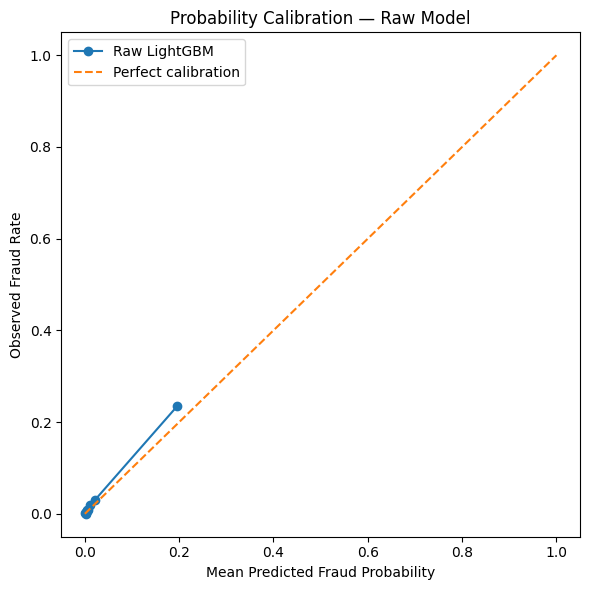

In [29]:
# Plots the reliability diagrams for the calculated raw probabilities

prob_true_raw, prob_pred_raw = calibration_curve(
    y_decision,
    decision_raw,
    n_bins=10,
    strategy="quantile"
)

fig, ax = plt.subplots(figsize=(6, 6))

ax.plot(
    prob_pred_raw,
    prob_true_raw,
    marker="o",
    label="Raw LightGBM"
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

ax.set_title(
    "Probability Calibration — Raw Model"
)

ax.set_xlabel(
    "Mean Predicted Fraud Probability"
)

ax.set_ylabel(
    "Observed Fraud Rate"
)

ax.legend()

plt.tight_layout()
plt.show()

### 7.2 Probability Calibration

Platt scaling and isotonic regression are fitted on days **128–141** and
compared on the later decision-selection period, days **142–154**.

Calibration changes probability estimates, not transaction ranking.

In [30]:
# Clips the desired probabilities from calibration and decision periods

EPSILON = 1e-6

cal_fit_clipped = np.clip(
    cal_fit_raw,
    EPSILON,
    1 - EPSILON
)

decision_clipped = np.clip(
    decision_raw,
    EPSILON,
    1 - EPSILON
)

In [31]:
# Uses the clipped probabilities as calibration input
# for the Platt calibrator model

platt_model = LogisticRegression()

platt_model.fit(
    logit(cal_fit_clipped).reshape(-1, 1),
    y_cal_fit
)

decision_platt = (
    platt_model.predict_proba(
        logit(
            decision_clipped
        ).reshape(-1, 1)
    )[:, 1]
)

In [32]:
# Uses the calculated raw probabilities as calibration input
# for the Isotonic calibrator model

isotonic_model = IsotonicRegression(
    out_of_bounds="clip"
)

isotonic_model.fit(
    cal_fit_raw,
    y_cal_fit
)

decision_isotonic = isotonic_model.predict(
    decision_raw
)

In [33]:
# Compares the two calibrators and the original selected model

calibration_comparison = pd.DataFrame([
    {
        "method": "Raw LightGBM",
        **calibration_metrics(
            y_decision,
            decision_raw
        )
    },
    {
        "method": "Platt scaling",
        **calibration_metrics(
            y_decision,
            decision_platt
        )
    },
    {
        "method": "Isotonic regression",
        **calibration_metrics(
            y_decision,
            decision_isotonic
        )
    }
])

display(
    calibration_comparison
)

calibration_comparison.to_csv(
    TABLES_DIR
    / "nb03_calibration_comparison.csv",
    index=False,
    float_format="%.6f"
)

,method,brier_score,log_loss
0,Raw LightGBM,0.0195,0.0812
1,Platt scaling,0.0196,0.0807
2,Isotonic regression,0.0198,0.0835


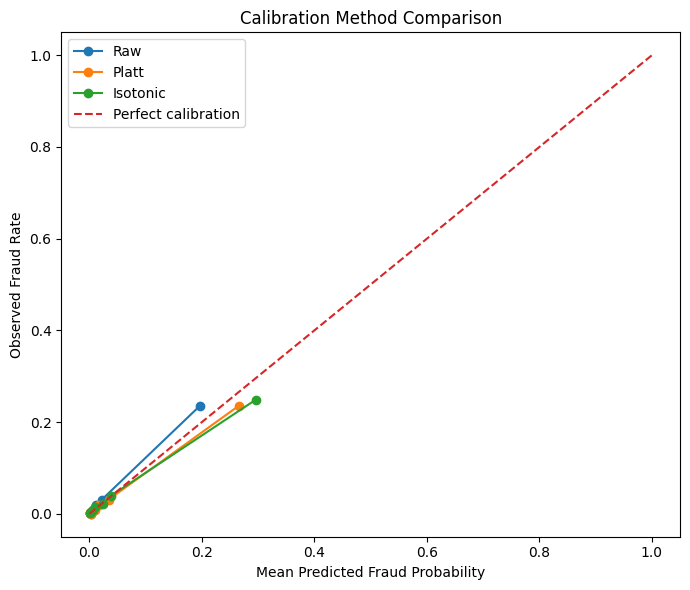

In [34]:
fig, ax = plt.subplots(figsize=(7, 6))

for label, probabilities in [
    ("Raw", decision_raw),
    ("Platt", decision_platt),
    ("Isotonic", decision_isotonic)
]:

    prob_true, prob_pred = calibration_curve(
        y_decision,
        probabilities,
        n_bins=10,
        strategy="quantile"
    )

    ax.plot(
        prob_pred,
        prob_true,
        marker="o",
        label=label
    )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

ax.set_title(
    "Calibration Method Comparison"
)

ax.set_xlabel(
    "Mean Predicted Fraud Probability"
)

ax.set_ylabel(
    "Observed Fraud Rate"
)

ax.legend()

plt.tight_layout()
plt.show()

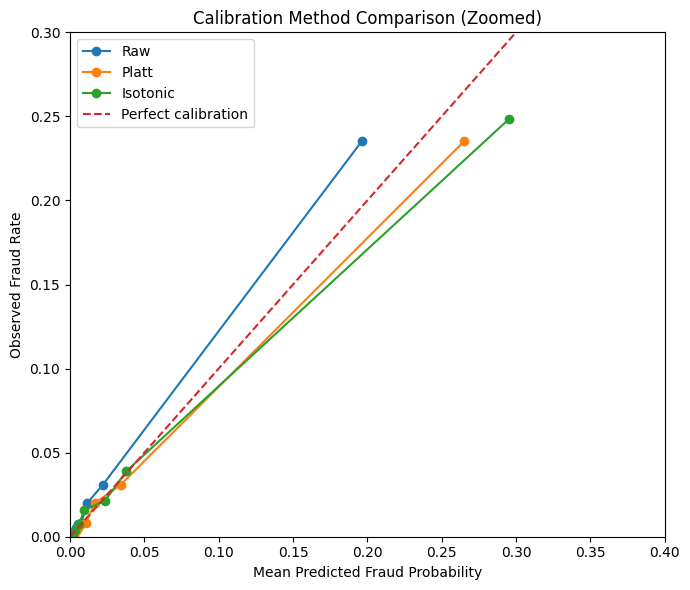

In [35]:
fig, ax = plt.subplots(figsize=(7, 6))

for label, probabilities in [
    ("Raw", decision_raw),
    ("Platt", decision_platt),
    ("Isotonic", decision_isotonic)
]:
    prob_true, prob_pred = calibration_curve(
        y_decision,
        probabilities,
        n_bins=10,
        strategy="quantile"
    )

    ax.plot(
        prob_pred,
        prob_true,
        marker="o",
        label=label
    )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

ax.set_title("Calibration Method Comparison (Zoomed)")
ax.set_xlabel("Mean Predicted Fraud Probability")
ax.set_ylabel("Observed Fraud Rate")

ax.set_xlim(0.0, 0.4)
ax.set_ylim(0.0, 0.3)

ax.legend()
plt.tight_layout()
fig.savefig(
    FIGURES_DIR
    / "nb03_calibration_method_comparison.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

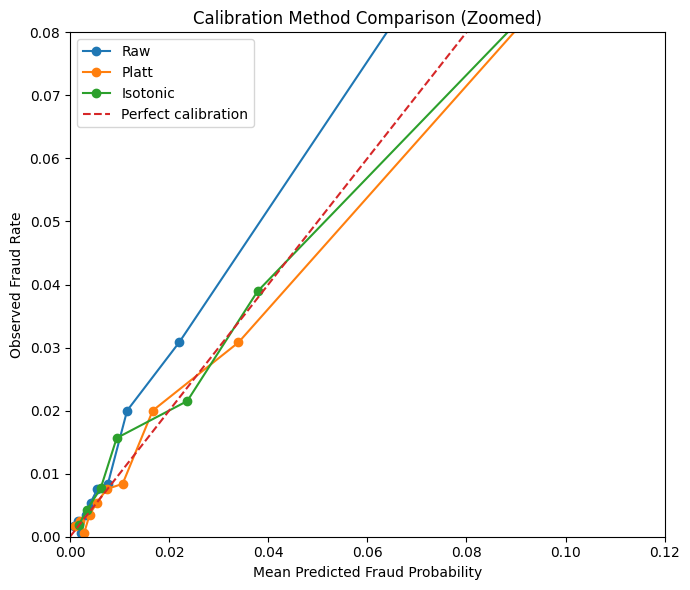

In [36]:
fig, ax = plt.subplots(figsize=(7, 6))

for label, probabilities in [
    ("Raw", decision_raw),
    ("Platt", decision_platt),
    ("Isotonic", decision_isotonic)
]:
    prob_true, prob_pred = calibration_curve(
        y_decision,
        probabilities,
        n_bins=10,
        strategy="quantile"
    )

    ax.plot(
        prob_pred,
        prob_true,
        marker="o",
        label=label
    )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

ax.set_title("Calibration Method Comparison (Zoomed)")
ax.set_xlabel("Mean Predicted Fraud Probability")
ax.set_ylabel("Observed Fraud Rate")

ax.set_xlim(0.0, 0.12)
ax.set_ylim(0.0, 0.08)

ax.legend()
plt.tight_layout()
plt.show()

#### Probability Calibration Findings

On the decision-selection period, the selected LightGBM achieves **0.9160
ROC-AUC** and **0.5636 average precision** against **3.16% fraud prevalence**.

The raw model has the lowest Brier score (**0.0195**), while Platt scaling gives
the lowest log loss (**0.0807**) with an almost identical Brier score
(**0.0196**). Isotonic regression performs worse on both measures.

Platt scaling is therefore retained as a modest probability adjustment. It does
not improve ranking performance; it only changes the probability scale.

Ranking performance is lower than on internal validation, but no model change is
made because model selection is already closed.

In [37]:
calibration_in_the_large = pd.DataFrame({
    "method": [
        "Raw LightGBM",
        "Platt scaling",
        "Isotonic regression"
    ],
    "mean_predicted_pct": [
        decision_raw.mean() * 100,
        decision_platt.mean() * 100,
        decision_isotonic.mean() * 100
    ],
    "observed_fraud_rate_pct": [
        y_decision.mean() * 100,
        y_decision.mean() * 100,
        y_decision.mean() * 100
    ]
})

calibration_in_the_large[
    "difference_pp"
] = (
    calibration_in_the_large[
        "mean_predicted_pct"
    ]
    - calibration_in_the_large[
        "observed_fraud_rate_pct"
    ]
)

display(
    calibration_in_the_large
)

calibration_in_the_large.to_csv(
    TABLES_DIR
    / "nb03_calibration_in_the_large.csv",
    index=False,
    float_format="%.4f"
)

,method,mean_predicted_pct,observed_fraud_rate_pct,difference_pp
0,Raw LightGBM,2.5525,3.1574,-0.6049
1,Platt scaling,3.4919,3.1574,0.3345
2,Isotonic regression,3.5144,3.1574,0.3570


#### Calibration-in-the-Large

The raw model predicts an average fraud probability of **2.55%**, compared with
an observed rate of **3.16%**.

Platt scaling shifts the mean prediction to **3.49%**, reducing the absolute
prevalence error from about **0.60** to **0.33 percentage points**.

This supports the use of Platt scaling, although the calibration improvement is
small rather than dramatic.

### 7.3 Operating Threshold and Business Decision Analysis

A calibrated probability still needs an operating rule before it becomes an
alert.

Threshold and review-capacity decisions are made using only days **142–154**.
The final holdout is reserved from these decisions.

The analysis considers precision, recall, false-positive burden, fraud capture,
and investigation workload under several operating scenarios.

In [38]:
# Creates a reusable threshold evaluator

def evaluate_threshold(
    y_true,
    probabilities,
    threshold
):
    predictions = (
        probabilities >= threshold
    ).astype("int8")

    tp = int(
        ((predictions == 1) & (y_true == 1)).sum()
    )

    fp = int(
        ((predictions == 1) & (y_true == 0)).sum()
    )

    tn = int(
        ((predictions == 0) & (y_true == 0)).sum()
    )

    fn = int(
        ((predictions == 0) & (y_true == 1)).sum()
    )

    alerts = tp + fp
    n = len(y_true)

    precision = (
        tp / alerts
        if alerts > 0
        else 0
    )

    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else 0
    )

    return {
        "threshold": threshold,
        "alerts": alerts,
        "alert_rate_pct":
            alerts / n * 100,
        "true_positives": tp,
        "false_positives": fp,
        "true_negatives": tn,
        "false_negatives": fn,
        "precision_pct":
            precision * 100,
        "recall_pct":
            recall * 100
    }

In [39]:
# General threshold grid used to inspect precision, recall
# and review workload across the operating range.

threshold_grid = np.linspace(
    0.01,
    0.90,
    90
)

threshold_results = pd.DataFrame([
    evaluate_threshold(
        y_decision.to_numpy(),
        decision_platt,
        threshold
    )
    for threshold in threshold_grid
])

In [40]:
threshold_results[
    [
        "threshold",
        "alert_rate_pct",
        "precision_pct",
        "recall_pct",
        "true_positives",
        "false_positives",
        "false_negatives"
    ]
]

,threshold,alert_rate_pct,precision_pct,recall_pct,true_positives,false_positives,false_negatives
0,0.0100,36.3700,8.0645,92.8938,1085,12369,83
1,0.0200,21.4587,12.5724,85.4452,998,6940,170
2,0.0300,15.7412,16.3146,81.3356,950,4873,218
3,0.0400,12.7082,19.5065,78.5103,917,3784,251
4,0.0500,10.6969,22.3907,75.8562,886,3071,282
...,...,...,...,...,...,...,...
85,0.8600,0.8894,91.4894,25.7705,301,28,867
86,0.8700,0.8651,91.8750,25.1712,294,26,874
87,0.8800,0.8569,92.1136,25.0000,292,25,876
88,0.8900,0.8380,92.9032,24.6575,288,22,880


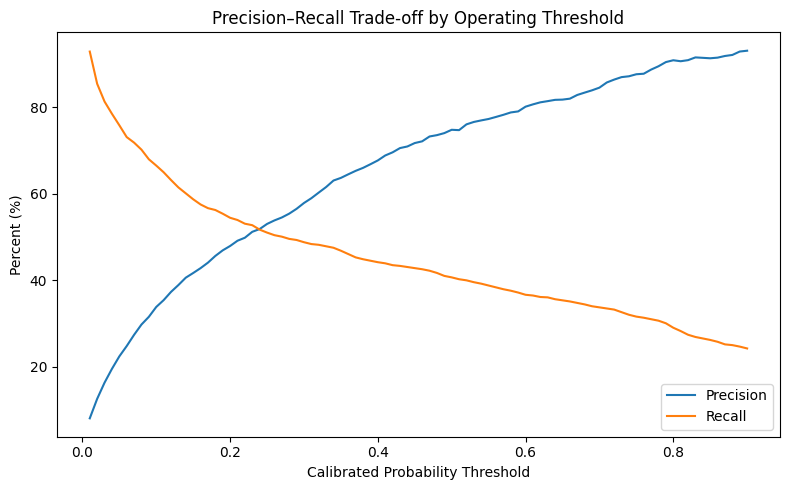

In [41]:
# Plots precision and recall against the different thresholds

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    threshold_results["threshold"],
    threshold_results["precision_pct"],
    label="Precision"
)

ax.plot(
    threshold_results["threshold"],
    threshold_results["recall_pct"],
    label="Recall"
)

ax.set_title(
    "Precision–Recall Trade-off by Operating Threshold"
)

ax.set_xlabel(
    "Calibrated Probability Threshold"
)

ax.set_ylabel(
    "Percent (%)"
)

ax.legend()

plt.tight_layout()

fig.savefig(
    FIGURES_DIR
    / "nb03_threshold_precision_recall_tradeoff.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

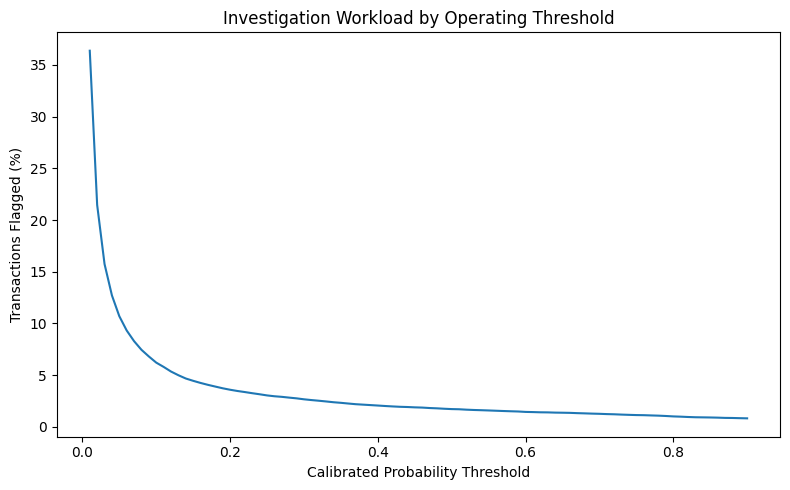

In [42]:
# Illustrates how the percentage of flagged transactions changes
# against different thresholds

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    threshold_results["threshold"],
    threshold_results["alert_rate_pct"]
)

ax.set_title(
    "Investigation Workload by Operating Threshold"
)

ax.set_xlabel(
    "Calibrated Probability Threshold"
)

ax.set_ylabel(
    "Transactions Flagged (%)"
)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR
    / "nb03_threshold_review_workload.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

### Capacity based scenarios

What happens if investigators can review only the top 1%, 2%, 5% or 10% of transactions? The model is evaluated under review capacities of **1%, 2%, 5%, and 10%** of transactions.

In [43]:
# Review-capacity scenarios evaluated on the decision period.

ALERT_RATES = [
    0.01,
    0.02,
    0.05,
    0.10
]

In [44]:
capacity_results = []

for alert_rate in ALERT_RATES:

    threshold = np.quantile(
        decision_platt,
        1 - alert_rate
    )

    result = evaluate_threshold(
        y_decision.to_numpy(),
        decision_platt,
        threshold
    )

    result["target_alert_rate_pct"] = (
        alert_rate * 100
    )

    capacity_results.append(result)

capacity_table = pd.DataFrame(
    capacity_results
)


In [45]:
# Quantifies how much more fraud-heavy the review queue is compared with the general population.

decision_fraud_rate = (
    y_decision.mean()
)

capacity_table["fraud_enrichment"] = (
    capacity_table["precision_pct"] / 100
    / decision_fraud_rate
)

In [46]:
capacity_display_cols = [
    "target_alert_rate_pct",
    "threshold",
    "alerts",
    "precision_pct",
    "recall_pct",
    "false_positives",
    "false_negatives",
    "fraud_enrichment"
]

display(
    capacity_table[
        capacity_display_cols
    ]
)

capacity_table[
    capacity_display_cols
].to_csv(
    TABLES_DIR
    / "nb03_review_capacity_scenarios.csv",
    index=False,
    float_format="%.4f"
)

,target_alert_rate_pct,threshold,alerts,precision_pct,recall_pct,false_positives,false_negatives,fraud_enrichment
0,1.0000,0.8021,370,90.8108,28.7671,34,832,28.7609
1,2.0000,0.4125,740,69.0541,43.7500,229,657,21.8703
2,5.0000,0.1295,1850,38.8108,61.4726,1132,450,12.2919
3,10.0000,0.0546,3700,23.5405,74.5719,2829,297,7.4556


#### Review-Capacity Findings

Reviewing only the highest-risk **1%** of transactions produces **90.8%
precision**, but captures only **28.8%** of fraud.

At a **5% review capacity**, recall rises to **61.5%** while precision remains
**38.8%**. The review queue is about **12.3× more fraud-dense** than the general
transaction population.

Increasing capacity to 10% raises recall to **74.6%**, but doubles review volume
and reduces precision to **23.5%**.

The **5% policy** is used as the primary operating scenario because it provides
a reasonable middle ground between fraud capture and review workload. It is an
illustrative capacity assumption, not a universal optimum.

#### Cost-Sensitivity Scenarios

In [47]:
# Illustrative false-negative to false-positive cost ratios.

COST_RATIOS = [
    20,
    50,
    100
]

# Use a finer grid for cost sensitivity because the preferred
# thresholds under high missed-fraud costs are close to zero.

cost_threshold_grid = np.linspace(
    0.001,
    0.50,
    500
)

cost_threshold_results = pd.DataFrame([
    evaluate_threshold(
        y_decision.to_numpy(),
        decision_platt,
        threshold
    )
    for threshold in cost_threshold_grid
])

In [48]:
cost_results = []

for cost_ratio in COST_RATIOS:

    temp = cost_threshold_results.copy()

    temp["relative_cost"] = (
        temp["false_positives"]
        + cost_ratio
        * temp["false_negatives"]
    )

    best_row = temp.loc[
        temp["relative_cost"].idxmin()
    ].copy()

    best_row["fn_fp_cost_ratio"] = cost_ratio

    cost_results.append(best_row)

cost_table = (
    pd.DataFrame(
        cost_results
    )
    .reset_index(
        drop=True
    )
)

In [49]:
cost_display_cols = [
    "fn_fp_cost_ratio",
    "threshold",
    "alert_rate_pct",
    "precision_pct",
    "recall_pct",
    "false_positives",
    "false_negatives",
    "relative_cost"
]

display(
    cost_table[
        cost_display_cols
    ]
)

cost_table[
    cost_display_cols
].to_csv(
    TABLES_DIR
    / "nb03_cost_sensitivity_scenarios.csv",
    index=False,
    float_format="%.4f"
)

,fn_fp_cost_ratio,threshold,alert_rate_pct,precision_pct,recall_pct,false_positives,false_negatives,relative_cost
0,20.0000,0.0480,11.0321,21.9064,76.5411,"3,187.0000",274.0000,"8,667.0000"
1,50.0000,0.0190,22.3697,12.1813,86.3014,"7,267.0000",160.0000,"15,267.0000"
2,100.0000,0.0120,31.6312,9.1274,91.4384,"10,633.0000",100.0000,"20,633.0000"


#### Cost-Sensitivity Findings

Higher assumed costs for missed fraud lead to lower operating thresholds and
larger review queues.

At a **20:1** false-negative-to-false-positive cost ratio, the preferred
threshold is about **0.048**, with **76.5% recall** and an **11.0% alert rate**.

At **50:1**, recall rises to **86.3%** with a **22.4% alert rate**. At **100:1**,
recall reaches **91.4%**, but nearly one-third of transactions are flagged.

These ratios are illustrative sensitivity assumptions, not estimates of the
dataset provider's real costs.

In [50]:
# Defines the selected operating threshold

SELECTED_ALERT_RATE = 0.05

SELECTED_THRESHOLD = np.quantile(
    decision_platt,
    1 - SELECTED_ALERT_RATE
)

print(
    f"Selected review capacity: "
    f"{SELECTED_ALERT_RATE:.0%}"
)

print(
    f"Locked probability threshold: "
    f"{SELECTED_THRESHOLD:.4f}"
)

Selected review capacity: 5%
Locked probability threshold: 0.1295


#### Selected Operating Policy

The primary operating policy reviews the highest-risk **5%** of transactions.

On the decision-selection period this captures **61.5% of fraud** at **38.8%
precision**, with a **12.3× fraud enrichment** in the review queue.

The corresponding Platt-calibrated threshold is approximately **0.1295** and is
fixed before final-holdout evaluation.


### 7.4 Final Holdout Evaluation

In [51]:
# Creates the holdout data

X_holdout = df.loc[
    holdout_mask,
    feature_cols
].copy()

y_holdout = df.loc[
    holdout_mask,
    TARGET
].copy()

print("Holdout shape:", X_holdout.shape)
print(
    f"Holdout fraud prevalence: "
    f"{y_holdout.mean():.4%}"
)

Holdout shape: (78542, 434)
Holdout fraud prevalence: 3.5319%


In [52]:
# Apply the development-derived category schema.
# Categories first observed after day 127 map to __UNSEEN__.

X_holdout = apply_category_schema(
    X_holdout,
    final_category_schema
)

In [53]:
# Generate raw predictions on the final holdout.

holdout_raw = final_model.predict_proba(
    X_holdout
)[:, 1]

In [54]:
# Applies the already fitted Platt calibrator

holdout_clipped = np.clip(
    holdout_raw,
    EPSILON,
    1 - EPSILON
)

holdout_platt = (
    platt_model.predict_proba(
        logit(
            holdout_clipped
        ).reshape(-1, 1)
    )[:, 1]
)

In [55]:
# Ranks the performance of the final model on the holdout data

holdout_roc_auc = roc_auc_score(
    y_holdout,
    holdout_raw
)

holdout_pr_auc = average_precision_score(
    y_holdout,
    holdout_raw
)

holdout_prevalence = y_holdout.mean()

print(
    f"Final holdout ROC-AUC: "
    f"{holdout_roc_auc:.4f}"
)

print(
    f"Final holdout average precision: "
    f"{holdout_pr_auc:.4f}"
)

print(
    f"Holdout fraud prevalence: "
    f"{holdout_prevalence:.4f}"
)

print(
    f"Average precision / prevalence lift: "
    f"{holdout_pr_auc / holdout_prevalence:.1f}x"
)

Final holdout ROC-AUC: 0.9119
Final holdout average precision: 0.5468
Holdout fraud prevalence: 0.0353
Average precision / prevalence lift: 15.5x


In [56]:
# Evaluate raw and Platt-calibrated probabilities on the final holdout.

holdout_calibration = pd.DataFrame([
    {
        "method": "Raw LightGBM",
        "brier_score": brier_score_loss(
            y_holdout,
            holdout_raw
        ),
        "log_loss": log_loss(
            y_holdout,
            holdout_raw
        ),
        "mean_predicted_probability":
            holdout_raw.mean()
    },
    {
        "method": "Platt scaling",
        "brier_score": brier_score_loss(
            y_holdout,
            holdout_platt
        ),
        "log_loss": log_loss(
            y_holdout,
            holdout_platt
        ),
        "mean_predicted_probability":
            holdout_platt.mean()
    }
])

holdout_calibration["observed_fraud_rate"] = (
    holdout_prevalence
)

display(
    holdout_calibration
)

holdout_calibration.to_csv(
    TABLES_DIR
    / "nb03_holdout_calibration.csv",
    index=False,
    float_format="%.6f"
)

,method,brier_score,log_loss,mean_predicted_probability,observed_fraud_rate
0,Raw LightGBM,0.0225,0.0918,0.0283,0.0353
1,Platt scaling,0.0226,0.0915,0.0386,0.0353


In [57]:
# Applies the selected operating threshold
# applying the threshold learned earlier

holdout_operating_metrics = evaluate_threshold(
    y_holdout.to_numpy(),
    holdout_platt,
    SELECTED_THRESHOLD
)

holdout_operating_metrics

{'threshold': np.float64(0.12951133886123423),
 'alerts': 4450,
 'alert_rate_pct': 5.665758447709505,
 'true_positives': 1714,
 'false_positives': 2736,
 'true_negatives': 73032,
 'false_negatives': 1060,
 'precision_pct': 38.51685393258427,
 'recall_pct': 61.788031723143476}

In [58]:
# Adds fraud enrichment on the holdout subset

holdout_precision = (
    holdout_operating_metrics["precision_pct"]
    / 100
)

holdout_enrichment = (
    holdout_precision
    / holdout_prevalence
)

print(
    f"Final holdout fraud enrichment: "
    f"{holdout_enrichment:.2f}x"
)

Final holdout fraud enrichment: 10.91x


In [59]:
# Evaluate the already locked policy on the
# decision-selection period for comparison with the holdout.

selected_decision_metrics = evaluate_threshold(
    y_decision.to_numpy(),
    decision_platt,
    SELECTED_THRESHOLD
)

print(
    f"Locked review capacity: "
    f"{SELECTED_ALERT_RATE:.0%}"
)

print(
    f"Locked probability threshold: "
    f"{SELECTED_THRESHOLD:.4f}"
)

selected_decision_metrics

Locked review capacity: 5%
Locked probability threshold: 0.1295


{'threshold': np.float64(0.12951133886123423),
 'alerts': 1850,
 'alert_rate_pct': 5.001081314878893,
 'true_positives': 718,
 'false_positives': 1132,
 'true_negatives': 34692,
 'false_negatives': 450,
 'precision_pct': 38.81081081081081,
 'recall_pct': 61.47260273972602}

In [60]:
decision_vs_holdout = pd.DataFrame([
    {
        "period": "Decision selection",
        "fraud_prevalence_pct":
            y_decision.mean() * 100,
        "roc_auc":
            decision_raw_roc,
        "average_precision":
            decision_raw_pr,
        "alert_rate_pct":
            selected_decision_metrics[
                "alert_rate_pct"
            ],
        "precision_pct":
            selected_decision_metrics[
                "precision_pct"
            ],
        "recall_pct":
            selected_decision_metrics[
                "recall_pct"
            ],
        "fraud_enrichment":
            (
                selected_decision_metrics[
                    "precision_pct"
                ] / 100
            ) / y_decision.mean()
    },
    {
        "period": "Final holdout",
        "fraud_prevalence_pct":
            y_holdout.mean() * 100,
        "roc_auc":
            holdout_roc_auc,
        "average_precision":
            holdout_pr_auc,
        "alert_rate_pct":
            holdout_operating_metrics[
                "alert_rate_pct"
            ],
        "precision_pct":
            holdout_operating_metrics[
                "precision_pct"
            ],
        "recall_pct":
            holdout_operating_metrics[
                "recall_pct"
            ],
        "fraud_enrichment":
            holdout_enrichment
    }
])

display(
    decision_vs_holdout
)

decision_vs_holdout.to_csv(
    TABLES_DIR
    / "nb03_decision_vs_holdout.csv",
    index=False,
    float_format="%.4f"
)

,period,fraud_prevalence_pct,roc_auc,average_precision,alert_rate_pct,precision_pct,recall_pct,fraud_enrichment
0,Decision selection,3.1574,0.9160,0.5636,5.0011,38.8108,61.4726,12.2919
1,Final holdout,3.5319,0.9119,0.5468,5.6658,38.5169,61.7880,10.9055


In [61]:
decision_vs_holdout.set_index(
    "period"
).T

period,Decision selection,Final holdout
fraud_prevalence_pct,3.1574,3.5319
roc_auc,0.9160,0.9119
average_precision,0.5636,0.5468
alert_rate_pct,5.0011,5.6658
precision_pct,38.8108,38.5169
recall_pct,61.4726,61.7880
fraud_enrichment,12.2919,10.9055


#### Final Holdout Findings

The locked system is evaluated on days **155–182** without further model,
calibration, or threshold changes.

The final model achieves **0.9119 ROC-AUC** and **0.5468 average precision**
against **3.53% fraud prevalence**.

The fixed threshold of approximately **0.1295** flags **5.67%** of holdout
transactions, producing **38.52% precision** and **61.79% recall**. These values
are very close to the decision-selection results of **38.81% precision** and
**61.47% recall**.

The flagged holdout queue is **10.9× more fraud-dense** than the full holdout
population.

Platt scaling also remains reasonably stable: mean predicted fraud probability
moves from **2.83% raw** to **3.86% calibrated**, compared with an observed rate
of **3.53%**.

The main result is that the locked operating behavior remains stable on the
later holdout period.

In [62]:
FINAL_SYSTEM = {
    "model": "LightGBM",
    "num_leaves": 63,
    "n_estimators": 814,
    "learning_rate": 0.03,
    "calibration": "Platt scaling",
    "operating_policy": "5% review capacity",
    "probability_threshold": float(SELECTED_THRESHOLD)
}

final_system_table = pd.DataFrame({
    "component":
        list(
            FINAL_SYSTEM.keys()
        ),
    "value":
        list(
            FINAL_SYSTEM.values()
        )
})

final_system_table.to_csv(
    TABLES_DIR
    / "nb03_final_system_config.csv",
    index=False
)

FINAL_SYSTEM

{'model': 'LightGBM',
 'num_leaves': 63,
 'n_estimators': 814,
 'learning_rate': 0.03,
 'calibration': 'Platt scaling',
 'operating_policy': '5% review capacity',
 'probability_threshold': 0.12951133886123423}

## 8. Model Explainability and Error Analysis

The fraud-risk system has already been finalized and evaluated on the reserved
final holdout. Explainability and error analysis are therefore post-hoc: none
of the findings below is used to change feature engineering, model selection,
calibration, or the operating threshold.

The analysis addresses four questions:

1. Which features contribute most strongly to the LightGBM model globally?
2. Which features have the greatest average impact on individual predictions?
3. What drives representative true-positive, false-positive, and false-negative
   decisions?
4. How do detected and missed fraudulent transactions differ?

Because many IEEE-CIS variables are anonymized, feature attribution identifies
which variables the model relies upon but cannot always provide a direct
business interpretation of their underlying meaning.

### 8.1 Global Feature Importance

Two complementary importance measures are used.

**LightGBM gain importance** measures how much splits using a feature improve
the tree objective during training.

**Mean absolute SHAP contribution** measures how strongly a feature affects
individual model scores on average across a sample of holdout transactions.

The rankings need not be identical because they measure different aspects of
model behavior.

In [63]:
feature_importance = pd.DataFrame({
    "feature": final_model.booster_.feature_name(),
    "gain": final_model.booster_.feature_importance(
        importance_type="gain"
    ),
    "splits": final_model.booster_.feature_importance(
        importance_type="split"
    )
})

feature_importance["gain_pct"] = (
    feature_importance["gain"]
    / feature_importance["gain"].sum()
    * 100
)

feature_importance = feature_importance.sort_values(
    "gain",
    ascending=False
).reset_index(drop=True)

feature_importance.head(20)

,feature,gain,splits,gain_pct
0,V258,"175,137.8705",64,10.1557
1,C1,"69,712.2663",709,4.0424
2,DeviceInfo,"67,222.5225",1641,3.8980
3,C14,"62,977.9769",511,3.6519
4,C13,"54,513.7769",966,3.1611
5,card2,"48,460.7797",2421,2.8101
6,TransactionDT,"46,979.3020",2367,2.7242
7,card1,"45,368.4609",2640,2.6308
8,V294,"42,215.3115",122,2.4479
9,R_emaildomain,"41,153.0010",377,2.3863


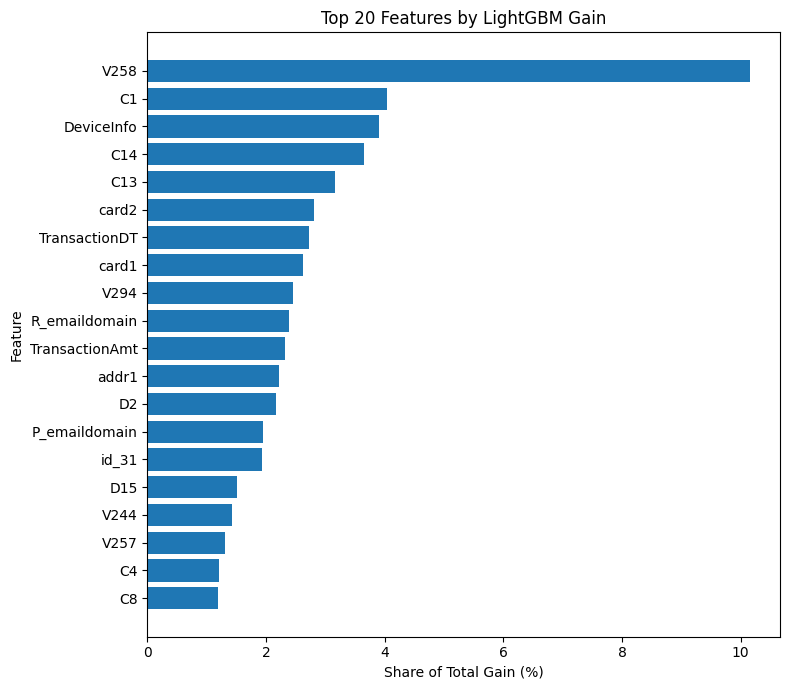

In [64]:
top_gain = (
    feature_importance
    .head(20)
    .sort_values("gain")
)

fig, ax = plt.subplots(figsize=(8, 7))

ax.barh(
    top_gain["feature"],
    top_gain["gain_pct"]
)

ax.set_title("Top 20 Features by LightGBM Gain")
ax.set_xlabel("Share of Total Gain (%)")
ax.set_ylabel("Feature")

plt.tight_layout()

fig.savefig(
    FIGURES_DIR
    / "nb03_top20_lightgbm_gain.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

#### Gain Importance

Gain importance shows which variables produced the largest improvements in the
LightGBM trees. It does not imply causality and can favor one variable over
correlated alternatives.

SHAP is used next as a second view of feature importance.

#### SHAP-Based Feature Contributions

In [65]:
# Uses a 5,000-row random holdout sample
# no point calculating SHAP values for all holdout rows

EXPLAIN_SAMPLE_SIZE = 5000

X_explain = X_holdout.sample(
    n=min(EXPLAIN_SAMPLE_SIZE, len(X_holdout)),
    random_state=42
)

In [66]:
# Creates the SHAP matrix on the 5000 row holdout sample

shap_matrix = final_model.booster_.predict(
    X_explain,
    pred_contrib=True
)

# Final column is the expected/base value

shap_values = shap_matrix[:, :-1]
shap_base_value = shap_matrix[0, -1]

print("SHAP matrix:", shap_values.shape)
print("Base value:", shap_base_value)

SHAP matrix: (5000, 434)
Base value: -5.0233997689033885


In [67]:
# Calculate mean absolute SHAP contribution:

shap_importance = pd.DataFrame({
    "feature": X_explain.columns,
    "mean_abs_shap": np.abs(
        shap_values
    ).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

shap_importance.head(20)

,feature,mean_abs_shap
0,TransactionAmt,0.2287
1,C13,0.2005
2,card6,0.1537
3,P_emaildomain,0.1290
4,C14,0.1251
5,V70,0.1240
6,card2,0.1134
7,C1,0.1105
8,D2,0.0986
9,TransactionDT,0.0975


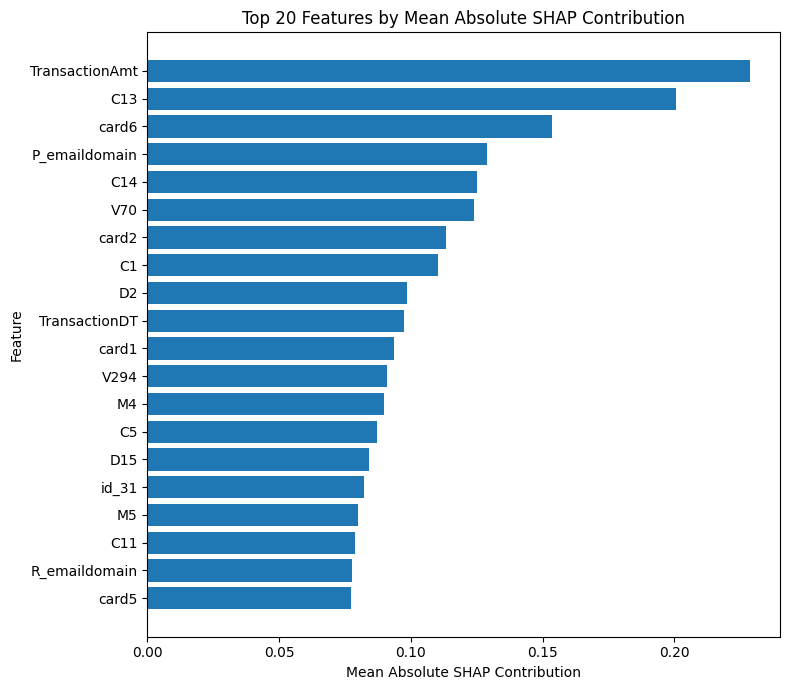

In [68]:
top_shap = (
    shap_importance
    .head(20)
    .sort_values("mean_abs_shap")
)

fig, ax = plt.subplots(figsize=(8, 7))

ax.barh(
    top_shap["feature"],
    top_shap["mean_abs_shap"]
)

ax.set_title(
    "Top 20 Features by Mean Absolute SHAP Contribution"
)

ax.set_xlabel(
    "Mean Absolute SHAP Contribution"
)

ax.set_ylabel("Feature")

plt.tight_layout()

fig.savefig(
    FIGURES_DIR
    / "nb03_top20_shap_importance.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

In [69]:
# Compare gain and mean absolute SHAP importance rankings.

importance_comparison = (
    feature_importance[
        ["feature", "gain_pct"]
    ]
    .merge(
        shap_importance,
        on="feature",
        how="inner"
    )
)

importance_comparison[
    "gain_rank"
] = (
    importance_comparison["gain_pct"]
    .rank(
        ascending=False,
        method="min"
    )
)

importance_comparison[
    "shap_rank"
] = (
    importance_comparison["mean_abs_shap"]
    .rank(
        ascending=False,
        method="min"
    )
)

importance_comparison_top20 = (
    importance_comparison
    .sort_values(
        "shap_rank"
    )
    .head(20)
)

display(
    importance_comparison_top20
)

importance_comparison_top20.to_csv(
    TABLES_DIR
    / "nb03_global_feature_importance_comparison.csv",
    index=False,
    float_format="%.6f"
)

,feature,gain_pct,mean_abs_shap,gain_rank,shap_rank
10,TransactionAmt,2.3182,0.2287,11.0000,1.0000
4,C13,3.1611,0.2005,5.0000,2.0000
23,card6,1.0486,0.1537,24.0000,3.0000
13,P_emaildomain,1.9426,0.1290,14.0000,4.0000
3,C14,3.6519,0.1251,4.0000,5.0000
37,V70,0.6447,0.1240,38.0000,6.0000
5,card2,2.8101,0.1134,6.0000,7.0000
1,C1,4.0424,0.1105,2.0000,8.0000
12,D2,2.1725,0.0986,13.0000,9.0000
6,TransactionDT,2.7242,0.0975,7.0000,10.0000


#### Global Feature-Importance Findings

Gain and SHAP importance agree on several influential variables, including
`C13`, `C14`, `card2`, `C1`, `D2`, `TransactionDT`, `card1`, and `V294`.

The rankings are not identical. `V258` contributes about **10.2% of total
LightGBM gain** but does not appear among the highest mean absolute SHAP
features, suggesting a small number of particularly valuable splits.

`TransactionAmt` shows the opposite pattern: it ranks 11th by gain but first by
mean absolute SHAP contribution, indicating a broader effect across individual
predictions.

Because many IEEE-CIS variables are anonymized, these results describe model
reliance rather than business meaning or causality.

### 8.2 Holdout Outcome Reconstruction

Each holdout transaction is assigned to one of four operating outcomes:

- **TP:** fraud correctly flagged;
- **FP:** legitimate transaction flagged;
- **FN:** fraud not flagged;
- **TN:** legitimate transaction not flagged.

In [70]:
# Use the selected calibrated probability and operational threshod
# on the holdout results

holdout_results = pd.DataFrame(
    {
        "y_true":
            y_holdout.to_numpy(),

        "raw_probability":
            holdout_raw,

        "calibrated_probability":
            holdout_platt
    },
    index=y_holdout.index
)

holdout_results["alert"] = (
    holdout_results[
        "calibrated_probability"
    ] >= SELECTED_THRESHOLD
).astype("int8")

In [71]:
conditions = [
    (
        (holdout_results["y_true"] == 1)
        & (holdout_results["alert"] == 1)
    ),
    (
        (holdout_results["y_true"] == 0)
        & (holdout_results["alert"] == 1)
    ),
    (
        (holdout_results["y_true"] == 1)
        & (holdout_results["alert"] == 0)
    ),
    (
        (holdout_results["y_true"] == 0)
        & (holdout_results["alert"] == 0)
    )
]

labels = [
    "True Positive",
    "False Positive",
    "False Negative",
    "True Negative"
]

holdout_results["outcome"] = np.select(
    conditions,
    labels,
    default="Unclassified"
)

holdout_results["outcome"].value_counts()

,count
outcome,
True Negative,73032
False Positive,2736
True Positive,1714
False Negative,1060


In [72]:
# Validates the total sum of the holdout results


assert len(holdout_results) == X_holdout.shape[0]

assert (
    holdout_results["outcome"] != "Unclassified"
).all()

assert (
    holdout_results["outcome"]
    .value_counts()
    .sum()
    == len(holdout_results)
)

print("Holdout outcome classification validated.")

Holdout outcome classification validated.


### 8.3 Detected vs Missed Fraud

The next analysis compares fraud that is successfully flagged with fraud that
falls below the selected operating threshold.

In [73]:
# Checks detected vs missed fraud transactions
# by combining a few interpretable structural variables with the predictions

error_analysis = (
    df.loc[
        holdout_results.index,
        [
            "TransactionAmt",
            "has_identity",
            "missing_pct",
            "ProductCD"
        ]
    ]
    .join(
        holdout_results[
            [
                "y_true",
                "calibrated_probability",
                "outcome"
            ]
        ]
    )
)

In [74]:
# Overview of the actual fraudulent transactions

fraud_error_summary = (
    error_analysis[
        error_analysis["y_true"] == 1
    ]
    .groupby("outcome")
    .agg(
        transactions=(
            "y_true",
            "size"
        ),
        median_transaction_amount=(
            "TransactionAmt",
            "median"
        ),
        identity_record_pct=(
            "has_identity",
            lambda x: x.mean() * 100
        ),
        mean_missing_pct=(
            "missing_pct",
            "mean"
        ),
        median_predicted_risk=(
            "calibrated_probability",
            "median"
        )
    )
)

fraud_error_summary.reset_index().to_csv(
    TABLES_DIR
    / "nb03_detected_vs_missed_fraud_summary.csv",
    index=False,
    float_format="%.4f"
)

In [75]:
fraud_error_summary.T

outcome,False Negative,True Positive
transactions,"1,060.0000","1,714.0000"
median_transaction_amount,75.0000,62.9560
identity_record_pct,33.4906,71.6453
mean_missing_pct,41.8357,31.7794
median_predicted_risk,0.0348,0.7632


#### Detected vs Missed Fraud Findings

Fraud that is successfully detected contains substantially more identity
information.

About **71.6% of true positives** have an identity record, compared with only
**33.5% of false negatives**. Mean missingness is also lower for detected fraud:
**31.8%** versus **41.8%**.

Median transaction amount differs less: **62.96** for true positives and
**75.00** for false negatives.

The strongest observed difference is therefore information availability rather
than transaction amount. These are associations, not evidence that missing
identity data causes fraud to be missed.

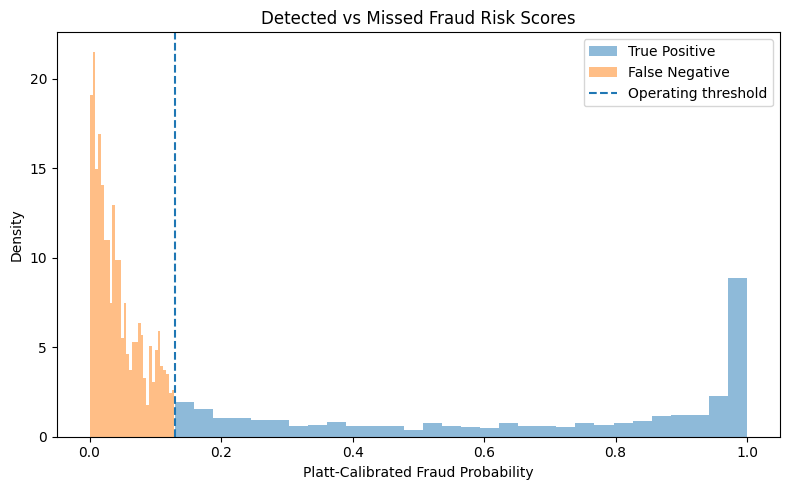

In [76]:
# Creates an error analysis plot showing
# the operational boundary responsible for false negatives

fig, ax = plt.subplots(figsize=(8, 5))

for outcome in [
    "True Positive",
    "False Negative"
]:
    error_analysis.loc[
        error_analysis["outcome"] == outcome,
        "calibrated_probability"
    ].plot(
        kind="hist",
        bins=30,
        alpha=0.5,
        density=True,
        label=outcome,
        ax=ax
    )

ax.axvline(
    SELECTED_THRESHOLD,
    linestyle="--",
    label="Operating threshold"
)

ax.set_title(
    "Detected vs Missed Fraud Risk Scores"
)

ax.set_xlabel(
    "Platt-Calibrated Fraud Probability"
)

ax.set_ylabel("Density")

ax.legend()

plt.tight_layout()

fig.savefig(
    FIGURES_DIR
    / "nb03_detected_vs_missed_fraud_scores.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

#### ProductCD Comparison

`ProductCD` is one of the available named transaction fields, so it can be
examined directly without assigning meaning to anonymized variables.

The comparison below checks whether fraud recall differs across its observed
categories.

In [77]:
# Compare ProductCD composition between detected and missed fraud.

fraud_product_mix = (
    pd.crosstab(
        error_analysis.loc[
            error_analysis["y_true"] == 1,
            "outcome"
        ],
        error_analysis.loc[
            error_analysis["y_true"] == 1,
            "ProductCD"
        ],
        normalize="index"
    )
    * 100
)

In [78]:
fraud_product_mix.T

outcome,False Negative,True Positive
ProductCD,,
C,22.0755,53.3839
H,4.0566,5.4259
R,2.8302,9.7433
S,5.0000,4.2007
W,66.0377,27.2462


In [79]:
fraud_by_product = (
    error_analysis[
        error_analysis["y_true"] == 1
    ]
    .groupby("ProductCD")
    .agg(
        fraud_transactions=(
            "y_true",
            "size"
        ),
        detected_fraud=(
            "outcome",
            lambda x: (x == "True Positive").sum()
        ),
        missed_fraud=(
            "outcome",
            lambda x: (x == "False Negative").sum()
        )
    )
)

fraud_by_product["recall_pct"] = (
    fraud_by_product["detected_fraud"]
    / fraud_by_product["fraud_transactions"]
    * 100
)

fraud_by_product_table = (
    fraud_by_product
    .sort_values(
        "recall_pct",
        ascending=False
    )
    .reset_index()
)

display(
    fraud_by_product_table
)

fraud_by_product_table.to_csv(
    TABLES_DIR
    / "nb03_fraud_recall_by_product.csv",
    index=False,
    float_format="%.4f"
)

,ProductCD,fraud_transactions,detected_fraud,missed_fraud,recall_pct
0,R,197,167,30,84.7716
1,C,1149,915,234,79.6345
2,H,136,93,43,68.3824
3,S,125,72,53,57.6000
4,W,1167,467,700,40.0171


In [80]:
fraud_by_identity = (
    error_analysis[
        error_analysis["y_true"] == 1
    ]
    .groupby("has_identity")
    .agg(
        fraud_transactions=("y_true", "size"),
        detected_fraud=(
            "outcome",
            lambda x: (x == "True Positive").sum()
        )
    )
)

fraud_by_identity["recall_pct"] = (
    fraud_by_identity["detected_fraud"]
    / fraud_by_identity["fraud_transactions"]
    * 100
)

fraud_by_identity_table = (
    fraud_by_identity
    .reset_index()
)

fraud_by_identity_table[
    "identity_status"
] = (
    fraud_by_identity_table[
        "has_identity"
    ]
    .map({
        0: "No identity record",
        1: "Identity record"
    })
)

fraud_by_identity_table = (
    fraud_by_identity_table[
        [
            "identity_status",
            "fraud_transactions",
            "detected_fraud",
            "recall_pct"
        ]
    ]
)

display(
    fraud_by_identity_table
)

fraud_by_identity_table.to_csv(
    TABLES_DIR
    / "nb03_fraud_recall_by_identity.csv",
    index=False,
    float_format="%.4f"
)

,identity_status,fraud_transactions,detected_fraud,recall_pct
0,No identity record,1191,486,40.8060
1,Identity record,1583,1228,77.5742


#### Subgroup Recall Findings

Fraud recall varies substantially across transaction groups.

Fraud with an identity record is detected at **77.6% recall**, compared with
**40.8%** when no identity record is available.

Recall also differs by `ProductCD`: approximately **84.8%** for `R`, **79.6%**
for `C`, and only **40.0%** for `W`.

Because `W` contains more than one thousand fraudulent holdout transactions,
this is a meaningful model limitation rather than a very small-sample effect.

These subgroup results are post-hoc diagnostics and are not used to change the
locked system.

### 8.4 Local Prediction Examples

Three holdout transactions are inspected:

- the highest-risk true positive
- the highest-risk false positive
- the highest-risk false negative, which is the missed fraud case closest to
  the operating threshold

In [81]:
tp_idx = (
    holdout_results[
        holdout_results["outcome"]
        == "True Positive"
    ]["calibrated_probability"]
    .idxmax()
)

fp_idx = (
    holdout_results[
        holdout_results["outcome"]
        == "False Positive"
    ]["calibrated_probability"]
    .idxmax()
)

fn_idx = (
    holdout_results[
        holdout_results["outcome"]
        == "False Negative"
    ]["calibrated_probability"]
    .idxmax()
)

case_indices = {
    "True Positive": tp_idx,
    "False Positive": fp_idx,
    "False Negative": fn_idx
}

In [82]:
# Summarize the selected local prediction examples.

case_summary = pd.DataFrame({
    label: holdout_results.loc[idx]
    for label, idx in case_indices.items()
}).T

case_summary

,y_true,raw_probability,calibrated_probability,alert,outcome
True Positive,1,0.9998,1.0000,1,True Positive
False Positive,0,0.9931,0.9982,1,False Positive
False Negative,1,0.0766,0.1292,0,False Negative


In [83]:
# Fetches the SHAP contribution of the edge case transactions

X_cases = X_holdout.loc[
    list(case_indices.values())
]

case_shap_matrix = (
    final_model.booster_.predict(
        X_cases,
        pred_contrib=True
    )
)

case_shap_values = (
    case_shap_matrix[:, :-1]
)

In [84]:
# Defines a function calculating SHAP contributions of the edge cases

def local_shap_table(
    X_cases,
    shap_values,
    row_position,
    top_n=12
):
    contributions = pd.DataFrame({
        "feature":
            X_cases.columns,
        "feature_value":
            X_cases.iloc[row_position]
            .astype(str)
            .values,
        "shap_contribution":
            shap_values[row_position]
    })

    contributions[
        "absolute_contribution"
    ] = (
        contributions[
            "shap_contribution"
        ].abs()
    )

    return (
        contributions
        .sort_values(
            "absolute_contribution",
            ascending=False
        )
        .head(top_n)
        .drop(
            columns="absolute_contribution"
        )
        .reset_index(
            drop=True
        )
    )

Positive SHAP values push the LightGBM raw score toward fraud, while negative
values push it toward the legitimate class.

The SHAP values shown here explain the underlying LightGBM score. They do **not**
directly explain the later Platt-calibrated probability.

Platt scaling is applied after the LightGBM prediction and preserves transaction
ranking, but the feature contributions reported here remain contributions to the
original model score.

In [85]:
for position, label in enumerate(
    case_indices.keys()
):
    print(f"\n{label}")
    display(
        local_shap_table(
            X_cases,
            case_shap_values,
            position
        )
    )


True Positive


,feature,feature_value,shap_contribution
0,V156,5.0,1.4033
1,V149,5.0,1.2796
2,R_emaildomain,gmail.com,0.9436
3,TransactionAmt,350.0,0.9339
4,C13,0.0,0.9098
5,C1,5.0,0.8598
6,C11,5.0,0.8121
7,C14,0.0,0.7589
8,V154,5.0,0.6244
9,V152,5.0,0.5184



False Positive


,feature,feature_value,shap_contribution
0,V258,6.0,1.5548
1,C14,0.0,0.8303
2,R_emaildomain,gmail.com,0.5702
3,C1,6.0,0.5435
4,C13,0.0,0.5098
5,V189,4.0,0.4725
6,id_03,3.0,0.3743
7,TransactionDT,15557752,0.3671
8,id_09,3.0,0.3435
9,V187,3.0,0.3433



False Negative


,feature,feature_value,shap_contribution
0,addr1,512.0,0.6010
1,C6,12.0,0.5855
2,V294,7.0,0.4517
3,M5,T,0.3689
4,card2,553.0,0.3348
5,TransactionAmt,29.0,-0.3126
6,C13,22.0,-0.2794
7,C5,2.0,-0.2788
8,V70,0.0,0.2304
9,C1,5.0,0.1800


#### Local Prediction Findings

The true positive receives a very high fraud score because several features push
the LightGBM prediction in the same direction.

The false positive also has a strongly fraud-like feature pattern, showing why a
legitimate transaction can still enter the review queue.

The false negative is a borderline case: its calibrated probability is
approximately **0.1292**, just below the locked threshold of **0.1295**. Some
features push the score toward fraud while others push it downward.

The examples show why the operating threshold should be treated as a business
decision applied to a continuous risk score rather than as a natural boundary
between fraud and legitimate transactions.

### Explainability and Error-Analysis Summary

The final LightGBM uses information from several feature families rather than
depending on one dominant predictor.

Gain importance and SHAP provide complementary views of model behavior. Error
analysis shows that fraud is much harder to detect when identity information is
missing, and recall is also substantially lower for `ProductCD = W`.

The local examples illustrate both highly confident errors and transactions that
fall just below the operating threshold.

These findings are retained as monitoring and future-development insights. The
already evaluated model, calibration method, and threshold remain unchanged.